<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">BOTTLENECK: STOCK AND SALES ANALYSIS</h1>
</div>

Bottleneck is an online wine and spirits shop. This notebook reconciles three exports for October (the ERP,
the website and a link table), checks their quality with automated rules, then analyses revenue, margins,
stock coverage and price anomalies to produce a prioritised list of actions.

It is the rebuilt version of my first analysis (OpenClassrooms Project 6), after an audit of that notebook
with two AI models (Project 13). The French original and the audit are summarised in the README.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 1 - Setup</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Libraries</h3>
</div>

In [1]:
# Libraries
from pathlib import Path
import sys
import numpy as np
import plotly.express as px
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa
from pandera.typing import Series
import warnings

# openpyxl warns about an Excel extension it does not read: harmless here
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Paths</h3>
</div>

In [2]:
# Paths, relative to the repository (the notebook sits in notebooks/)
ROOT = Path.cwd().parent
DATA_RAW = ROOT / "data" / "raw"
DATA_OUT = ROOT / "data" / "processed"
DATA_OUT.mkdir(parents=True, exist_ok=True)

In [3]:
# Check the paths
print("Data folder :", DATA_RAW.relative_to(ROOT))
print("Files found :", sorted(f.name for f in DATA_RAW.glob("*.xlsx")))

Data folder : data/raw
Files found : ['erp.xlsx', 'liaison.xlsx', 'web.xlsx']


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.3 - Project constants</h3>
</div>

In [4]:
# Constants: every assumption lives in one place
VAT_RATE = 0.20  # VAT assumption: 20%, the standard French rate on wine and spirits
MAD_THRESHOLD = 5  # price anomaly threshold (robust z-score)
MIN_MATCH_RATE = 0.95  # below this ERP/web match rate, the export is treated as degraded
RATIO_MIN, RATIO_MAX = (
    1.4,
    3.0,
)  # plausible range of the selling price / purchase price ratio

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 2 - Explore the raw files</h2>
</div>

In [5]:
# Raw files, before any correction
erp_raw = pd.read_excel(DATA_RAW / "erp.xlsx")
web_raw = pd.read_excel(DATA_RAW / "web.xlsx")
link_raw = pd.read_excel(DATA_RAW / "liaison.xlsx")

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - ERP export</h3>
</div>

In [6]:
# Dimensions
print(f"The table has {erp_raw.shape[0]} products")
print(f"The table has {erp_raw.shape[1]} columns")

The table has 825 products
The table has 6 columns


In [7]:
# Columns, data types and non-null counts
erp_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      825 non-null    int64  
 1   onsale_web      825 non-null    int64  
 2   price           825 non-null    float64
 3   stock_quantity  825 non-null    int64  
 4   stock_status    825 non-null    str    
 5   purchase_price  825 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 38.8 KB


In [8]:
# First five rows
erp_raw.head(5)

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


In [9]:
# Duplicated product_id?
print(f"product_id has {erp_raw['product_id'].duplicated().sum()} duplicates")

product_id has 0 duplicates


In [10]:
# Distinct values of stock_status
erp_raw["stock_status"].unique()

<StringArray>
['instock', 'outofstock']
Length: 2, dtype: str

In [11]:
# stock_status should follow stock_quantity
print("stock_status depends on stock_quantity")

stock_status depends on stock_quantity


In [12]:
# Rebuild the expected status from the quantity:
# 'outofstock' when the quantity is zero or below, 'instock' otherwise
erp_raw["stock_status_2"] = np.where(
    erp_raw["stock_quantity"] <= 0, "outofstock", "instock"
)

In [13]:
# Compare the two columns row by row
erp_raw["stock_status"] == erp_raw["stock_status_2"]

0       True
1       True
2       True
3       True
4      False
       ...  
820     True
821     True
822     True
823     True
824     True
Length: 825, dtype: bool

In [14]:
# True counts as 1, False as 0
matches = (erp_raw["stock_status"] == erp_raw["stock_status_2"]).sum()
print(matches)
print(f"{len(erp_raw) - matches} rows have a status that contradicts their quantity")

823
2 rows have a status that contradicts their quantity


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Variable: price</h3>
</div>

In [15]:
# Missing prices
print(f"Products with no price: {erp_raw['price'].isnull().sum()}")

Products with no price: 0


In [16]:
# Zero prices
print(f"Products with a zero price: {(erp_raw['price'] == 0).sum()}")

Products with a zero price: 0


In [17]:
# Negative prices
print(f"Products with a negative price: {(erp_raw['price'] < 0).sum()}")

Products with a negative price: 3


In [18]:
# Show the negative prices
erp_raw[erp_raw["price"] < 0]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
151,4233,0,-20.0,0,outofstock,10.33,outofstock
469,5017,0,-8.0,0,outofstock,4.34,outofstock
739,6594,0,-9.1,19,instock,4.61,instock


**Negative prices.** During exploration, the selling price looks roughly proportional to the purchase price.
The negative prices could be entry errors.

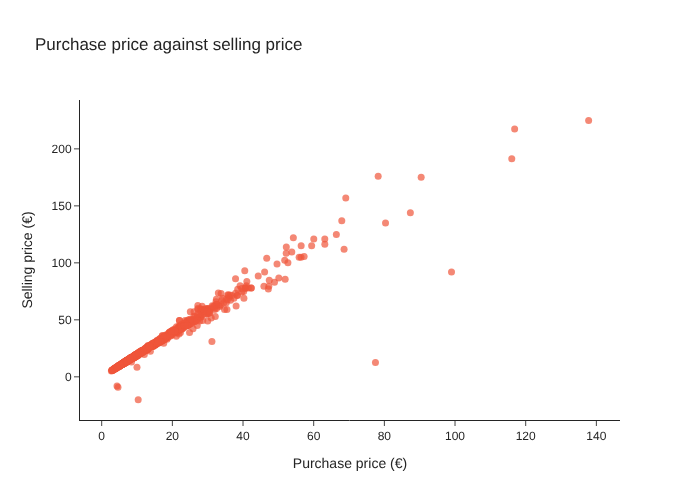

In [19]:
# Scatter plot of purchase price against selling price
fig = px.scatter(
    erp_raw,
    x="purchase_price",
    y="price",
    labels={"purchase_price": "Purchase price (€)", "price": "Selling price (€)"},
    title="Purchase price against selling price",
    template="simple_white",
)
fig.update_traces(marker=dict(size=7, opacity=0.7, color="#EF553B"))
fig.show()

The scatter plot shows a clear linear relationship between purchase and selling price. The three points below
the axis break that rule: a sign error is the likely explanation.

A fourth point also sits far below the line: a product bought at €77.48 and sold at €12.65. It is most likely
a misplaced decimal point.

These four anomalies are not fixed here. An automated rule fixes them in the next step.

In [20]:
# Lowest price
print(f"Lowest price : {erp_raw['price'].min()} €")

Lowest price : -20.0 €


In [21]:
# Highest price
print(f"Highest price: {int(erp_raw['price'].max())} €")

Highest price: 225 €


**Conclusion.** The price variable has 3 negative values and one product sold far below its purchase price.
The scatter plot shows a proportional relationship between the two prices, which points to entry errors rather
than commercial decisions. The four anomalies are handled by an automated rule in the next step, not fixed
one by one.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Variable: stock_quantity</h3>
</div>

In [22]:
# Missing stock
print(f"Products with no stock value: {erp_raw['stock_quantity'].isnull().sum()}")

Products with no stock value: 0


In [23]:
# Zero stock
print(f"Products with zero stock: {(erp_raw['stock_quantity'] == 0).sum()}")

Products with zero stock: 90


In [24]:
# Negative stock
print(f"Products with negative stock: {(erp_raw['stock_quantity'] < 0).sum()}")

Products with negative stock: 2


In [25]:
# Show the negative stock
erp_raw[erp_raw["stock_quantity"] < 0]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,stock_status_2
449,4973,0,10.0,-10,outofstock,4.96,outofstock
573,5700,1,44.5,-1,outofstock,22.30,outofstock


Two products show a negative stock, −10 and −1. This is not dirty data: a negative stock signals an oversale or
a synchronisation lag between the ERP and the website, so the raw value carries logistics information.

It is kept and reported as an alert, then neutralised only when the indicators are calculated. That is one of
the rules of the next step.

In [26]:
# Lowest stock
print(f"Lowest stock : {int(erp_raw['stock_quantity'].min())}")

Lowest stock : -10


In [27]:
# Highest stock
print(f"Highest stock: {int(erp_raw['stock_quantity'].max())}")

Highest stock: 145


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Variable: onsale_web</h3>
</div>

In [28]:
# Missing values and meaning of onsale_web
print(f"Products with no online status: {erp_raw['onsale_web'].isnull().sum()}")
print("onsale_web is a binary code: 1 if the product is sold online, 0 if it is not")

Products with no online status: 0
onsale_web is a binary code: 1 if the product is sold online, 0 if it is not


In [29]:
# Which columns to keep?
print(
    "All columns are kept. onsale_web separates the products sold online "
    "from the products sold in the shop only"
)

All columns are kept. onsale_web separates the products sold online from the products sold in the shop only


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Variable: purchase_price</h3>
</div>

In [30]:
# Missing purchase prices
print(f"Products with no purchase price: {erp_raw['purchase_price'].isnull().sum()}")

Products with no purchase price: 0


In [31]:
# Zero purchase prices
print(f"Products with a zero purchase price: {(erp_raw['purchase_price'] == 0).sum()}")

Products with a zero purchase price: 0


In [32]:
# Negative purchase prices
print(f"Products with a negative purchase price: {(erp_raw['purchase_price'] < 0).sum()}")

Products with a negative purchase price: 0


In [33]:
# Lowest purchase price
print(f"Lowest purchase price : {int(erp_raw['purchase_price'].min())} €")

Lowest purchase price : 2 €


In [34]:
# Highest purchase price
print(f"Highest purchase price: {int(erp_raw['purchase_price'].max())} €")

Highest purchase price: 137 €


**Conclusion.** No anomaly on the purchase price: it ranges from €2 to €137.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Website export</h3>
</div>

In [35]:
# Dimensions
print(f"The table has {web_raw.shape[1]} columns")
print(f"The table has {web_raw.shape[0]} rows")

The table has 29 columns
The table has 1513 rows


In [36]:
# Columns, data types and non-null counts
web_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sku                    1428 non-null   object        
 1   virtual                1513 non-null   int64         
 2   downloadable           1513 non-null   int64         
 3   rating_count           1513 non-null   int64         
 4   average_rating         1430 non-null   float64       
 5   total_sales            1430 non-null   float64       
 6   tax_status             716 non-null    str           
 7   tax_class              0 non-null      float64       
 8   post_author            1430 non-null   float64       
 9   post_date              1430 non-null   datetime64[us]
 10  post_date_gmt          1430 non-null   datetime64[us]
 11  post_content           0 non-null      float64       
 12  product_type           1429 non-null   str           
 13  post_title    

In [37]:
# Columns to keep
print("6 columns are kept: sku, total_sales, post_date, post_title, product_type and post_type.")
print("post_type separates product pages from image pages, which deduplication relies on.")

6 columns are kept: sku, total_sales, post_date, post_title, product_type and post_type.
post_type separates product pages from image pages, which deduplication relies on.


In [38]:
# Drop the other columns
web_columns = [
    "sku",
    "total_sales",
    "post_date",
    "post_title",
    "product_type",
    "post_type",
]
web_raw = web_raw[web_columns]

In [39]:
# New dataframe
web_raw.head(5)

,sku,total_sales,post_date,post_title,product_type,post_type
0,11862,3.0,2018-02-12 13:46:23,Gilles Robin Hermitage Rouge 2012,Vin,attachment
1,16057,5.0,2018-04-17 15:29:17,Domaine Pellé Sancerre Rouge La Croix Au Garde...,Vin,attachment
2,14692,5.0,2019-03-19 10:06:47,Château Fonréaud Bordeaux Blanc Le Cygne 2016,Vin,product
3,16295,14.0,2018-02-15 14:05:06,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,Vin,attachment
4,15328,2.0,2019-03-27 18:05:09,Agnès Levet Côte Rôtie Maestria 2017,Vin,product


In [40]:
# Values of the sku column
web_raw["sku"].unique()

array([11862, 16057, 14692, 16295, 15328, 15471, 16515, 16246, nan, 13572,
       16513, 16585, 16269, 15526, 12869, 15575, 11586, 14338, 15425,
       16560, 15361, 13809, 11587, 15022, 14323, 16342, 16029, 15475,
       13754, 14680, 15875, 9636, 13849, 13662, 16564, 13557, 15429,
       14712, 15032, 15481, 15448, 16580, 15441, 804, 15300, 13958, 16071,
       15678, 13895, 15711, 12882, 16053, 13766, 16247, 12640, 15292,
       15476, 15670, 16189, 16038, 14864, 16044, 15324, 15531, 15953,
       15413, 15733, 14366, 15895, 15892, 16472, 15185, 16010, 15793,
       15849, 12315, 15741, 15934, 15148, 15781, 15659, 15106, 15490,
       14507, 14149, 16307, 13736, 14090, 16037, 15758, 14661, 12587,
       15337, 15489, 15201, 16305, 16131, 13435, 15747, 12203, 14509,
       14768, 16262, 14561, 16505, 15717, 16129, 13460, 15871, 15940,
       11602, 13127, 13520, 15480, 13032, 15436, 15269, 15910, 19821,
       16263, 15138, 15146, 15126, 15482, 16186, 13905, 16540, 15856,
       1567

In [41]:
# SKUs that break the numeric format
print("4 rows (2 SKUs, each listed twice) break the numeric format: 13127-1 and bon-cadeau-25-euros")
web_raw[web_raw["sku"].astype(str).str.contains("-")]

4 rows (2 SKUs, each listed twice) break the numeric format: 13127-1 and bon-cadeau-25-euros


,sku,total_sales,post_date,post_title,product_type,post_type
272,13127-1,4.0,2020-06-09 15:42:04,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,Vin,product
842,bon-cadeau-25-euros,7.0,2018-06-01 13:53:46,Bon cadeau de 25€,Autre,attachment
1117,13127-1,4.0,2020-06-09 15:42:04,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,Vin,attachment
1387,bon-cadeau-25-euros,7.0,2018-06-01 13:53:46,Bon cadeau de 25€,NaN,product


In [42]:
# Is 13127-1 an error?
print("13127-1 is not an error: SKU 13127 also exists")
web_raw[web_raw["sku"].astype(str).str.contains("13127")]

13127-1 is not an error: SKU 13127 also exists


,sku,total_sales,post_date,post_title,product_type,post_type
123,13127,5.0,2018-02-12 11:18:33,Clos du Mont-Olivet Châteauneuf-du-Pape 2012,Vin,product
272,13127-1,4.0,2020-06-09 15:42:04,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,Vin,product
713,13127,5.0,2018-02-12 11:18:33,Clos du Mont-Olivet Châteauneuf-du-Pape 2012,Vin,attachment
1117,13127-1,4.0,2020-06-09 15:42:04,Clos du Mont-Olivet Châteauneuf-du-Pape 2007,Vin,attachment


SKU 13127-1 does not follow the numeric format of the other codes, but it is not an error: product 13127 also
exists. My first version renamed it 19823, an invented ID that exists neither in the ERP nor on the website.
That renaming is dropped: the code is kept as it is and treated as text.

In [43]:
# Rows without a SKU
web_raw[web_raw["sku"].isnull()]

,sku,total_sales,post_date,post_title,product_type,post_type
8,NaN,NaN,NaT,NaN,NaN,NaN
20,NaN,NaN,NaT,NaN,NaN,NaN
30,NaN,NaN,NaT,NaN,NaN,NaN
37,NaN,NaN,NaT,NaN,NaN,NaN
41,NaN,NaN,NaT,NaN,NaN,NaN
...,...,...,...,...,...,...
1384,NaN,NaN,NaT,NaN,NaN,NaN
1429,NaN,NaN,NaT,NaN,NaN,NaN
1432,NaN,NaN,NaT,NaN,NaN,NaN
1445,NaN,NaN,NaT,NaN,NaN,NaN


In [44]:
# Keep only the rows without a SKU
web_raw_no_sku = web_raw[web_raw["sku"].isnull()]

In [45]:
# What do they contain?
web_raw_no_sku.info()

<class 'pandas.DataFrame'>
Index: 85 entries, 8 to 1457
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   sku           0 non-null      object        
 1   total_sales   2 non-null      float64       
 2   post_date     2 non-null      datetime64[us]
 3   post_title    2 non-null      str           
 4   product_type  2 non-null      str           
 5   post_type     2 non-null      str           
dtypes: datetime64[us](1), float64(1), object(1), str(3)
memory usage: 4.6+ KB


Only 2 of the 85 rows without a SKU contain data.

In [46]:
# The two rows with data
web_raw_no_sku[web_raw_no_sku["total_sales"].notna()]

,sku,total_sales,post_date,post_title,product_type,post_type
1084,NaN,-56.0,2018-08-08 11:23:43,Pierre Jean Villa Condrieu Jardin Suspendu 2018,Vin,product
1087,NaN,-17.0,2018-07-31 12:07:23,Pierre Jean Villa Côte Rôtie Fongeant 2017,Vin,product


These two rows combine two anomalies: no SKU, and negative sales of −56 and −17. Without a SKU, there is no way
to know which product they belong to, or to confirm that they are returns.

They cannot be used in the analysis. In my first version they disappeared without a trace; they are now
reported as an alert and counted among the rejected rows before being removed.

In [47]:
# Duplicated SKUs?
print(f"Duplicated SKUs: {web_raw['sku'].duplicated().sum()}")

Duplicated SKUs: 798


In [48]:
# Duplicates on every column
print(f"Exact duplicates: {web_raw.duplicated().sum()}")

Exact duplicates: 82


In [49]:
# Imperfect duplicates: same SKU, different sales
web_sku = web_raw.dropna(subset=["sku"])
duplicates = web_sku[web_sku["sku"].duplicated(keep=False)]
distinct_sales = duplicates.groupby("sku")["total_sales"].nunique()
imperfect_duplicates = duplicates[duplicates["sku"].isin(distinct_sales[distinct_sales > 1].index)]
imperfect_duplicates.sort_values(["sku", "post_type"])

,sku,total_sales,post_date,post_title,product_type,post_type
523,1366,116.0,2018-02-13 13:45:31,Champagne Mailly Grand Cru Intemporelle 2010,Champagne,attachment
548,1366,6.0,2018-02-13 13:45:31,Champagne Mailly Grand Cru Intemporelle 2010,Champagne,product
114,14561,111.0,2018-09-01 15:34:55,Argentine Mendoza Alamos Torrontes 2017,Vin,attachment
1052,14561,11.0,2018-09-01 15:34:55,Argentine Mendoza Alamos Torrontes 2017,Vin,product
452,14950,122.0,2018-04-18 11:53:51,François Baur Pinot Noir Schlittweg 2017,Vin,attachment
999,14950,22.0,2018-04-18 11:53:51,François Baur Pinot Noir Schlittweg 2017,Vin,product
219,15346,22.0,2018-07-31 11:49:05,Albert Mann Pinot Noir Grand H 2017,Vin,attachment
843,15346,2.0,2018-07-31 11:49:05,Albert Mann Pinot Noir Grand H 2017,Vin,product


Of the 714 SKUs listed twice, only 4 show different sales on their two rows.

In [50]:
# Median and third quartile of total_sales
web_raw["total_sales"].describe()

count    1430.000000
mean        8.223077
std         6.721899
min       -56.000000
25%         5.000000
50%         8.000000
75%        11.000000
max       122.000000
Name: total_sales, dtype: float64

The median is 8 and the third quartile 11, which makes 116, 111 and 122 outliers. But the distribution is not the
right argument: in all four cases, the high value sits on the `attachment` row, the image page, and the low value
on the `product` row.

So the rule is structural, not statistical: keep the row where `post_type == "product"`. It applies to the whole
export, settles the 714 duplicates at once, and will work on any future export.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Link table</h3>
</div>

In [51]:
# Dimensions
print(f"The table has {link_raw.shape[0]} rows")
print(f"The table has {link_raw.shape[1]} columns")

The table has 825 rows
The table has 2 columns


In [52]:
# Columns, data types and non-null counts
link_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 825 entries, 0 to 824
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id_web      734 non-null    object
 1   product_id  825 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 13.0+ KB


In [53]:
# Duplicated product_id?
print(f"product_id has {link_raw['product_id'].duplicated().sum()} duplicates")

product_id has 0 duplicates


In [54]:
# Duplicated id_web?
print(f"id_web has {link_raw['id_web'].duplicated(keep=False).sum()} duplicated rows")

id_web has 91 duplicated rows


In [55]:
# Which id_web values are duplicated?
duplicated_id_web = link_raw[link_raw["id_web"].duplicated(keep=False)].sort_values("id_web")
print(duplicated_id_web.head(10))
print("The duplicated id_web values are all empty: products that are not sold online.")

    id_web  product_id
19     NaN        4055
49     NaN        4090
50     NaN        4092
119    NaN        4195
131    NaN        4209
151    NaN        4233
184    NaN        4278
185    NaN        4279
234    NaN        4565
238    NaN        4577
The duplicated id_web values are all empty: products that are not sold online.


In [56]:
# Products without a website match?
print(link_raw[link_raw["id_web"].isnull()])
print(f"{link_raw['id_web'].isnull().sum()} products have no website ID")

    id_web  product_id
19     NaN        4055
49     NaN        4090
50     NaN        4092
119    NaN        4195
131    NaN        4209
..     ...         ...
817    NaN        7196
818    NaN        7200
819    NaN        7201
820    NaN        7203
821    NaN        7204

[91 rows x 2 columns]
91 products have no website ID


**Conclusion.** The empty `id_web` values are products that are not sold online, so they have no website ID.

Exploration confirms the audit's findings: 3 negative prices, 2 negative stocks, 2 rows with negative sales and
no SKU, and apparent duplicates in the website export.

My first version fixed these one by one, by hand. The next step handles them with automated rules that run on
every load.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 3 - Automated quality control</h2>
</div>

Loading applies validation rules before handing over the data, with two levels of severity:

- **Blocking**: the file cannot be used (duplicated ID, missing or zero price, value outside its domain). Processing stops.
- **Alert**: the catalogue contains an occasional anomaly (unusual price, negative stock, inconsistent status). Processing continues and reports it.

This is deliberate: three mistyped prices should not stop the month's analysis.

| Rule | Checks | Level |
| ---- | ------ | ----- |
| R1 | `product_id` (ERP) and `sku` (website) are unique | Blocking |
| R2 | Every price is filled in and positive, once explainable entry errors are fixed | Blocking |
| R3 | Every purchase price is above zero | Blocking |
| R4 | The selling price / purchase price ratio stays within 5 robust z-scores of the catalogue | Alert |
| R5 | Stock is filled in; negative stock is reported, then set to zero for the indicators | Alert |
| R6 | `stock_status` only takes `instock` or `outofstock`, and matches the quantity | Blocking / alert |
| R7 | `onsale_web` only takes 0 or 1 | Blocking |
| R8 | At least 95% of the linked products are found in the website export | Blocking |
| R9 | Sales are never negative | Blocking |
| R10 | Every rejected row is counted and reported | Report |

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.1 - Validation schemas</h3>
</div>

In [57]:
# pandera validation rules


class ERPSchema(pa.DataFrameModel):
    """Blocking rules on the ERP export: if one fails, the file cannot be used."""

    product_id: Series[int] = pa.Field(unique=True)  # R1
    price: Series[float] = pa.Field(nullable=False)  # R2
    purchase_price: Series[float] = pa.Field(gt=0)  # R3
    stock_quantity: Series[int] = pa.Field(nullable=False)  # R5
    stock_status: Series[str] = pa.Field(isin=["instock", "outofstock"])  # R6
    onsale_web: Series[int] = pa.Field(isin=[0, 1])  # R7

    @pa.check("price", name="R2_positive_price")
    def positive_price(cls, s):
        return s > 0

    @pa.check("stock_quantity", name="R5_positive_stock")
    def positive_stock(cls, s):
        return s >= 0

    class Config:
        strict = False


class WebSchema(pa.DataFrameModel):
    """Rules on the website export, applied AFTER the post_type == 'product' filter."""

    sku: Series[str] = pa.Field(unique=True, nullable=True)  # R1
    total_sales: Series[float] = pa.Field(ge=0, nullable=True)  # R9

    class Config:
        strict = False

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.2 - Check functions (MAD, price anomalies, stock inconsistencies)</h3>
</div>

In [58]:
# Helper functions
def mad_scores(series):
    """Robust z-score: distance to the median divided by the MAD. Not pulled by extreme values."""
    median = series.median()
    mad = (series - median).abs().median()
    if mad == 0:
        return pd.Series(0.0, index=series.index)
    return 0.6745 * (series - median) / mad


def price_anomalies(df_erp, threshold=MAD_THRESHOLD):
    """R4: products whose selling / purchase price ratio departs from the catalogue's practice."""
    ratio = df_erp["price"] / df_erp["purchase_price"]
    z = mad_scores(ratio)
    suspect = df_erp.loc[z.abs() > threshold].copy()
    suspect["ratio"] = ratio
    suspect["mad_score"] = z
    return suspect.sort_values("mad_score")


def stock_inconsistencies(df_erp):
    """R6: zero stock shown as in stock, or the reverse."""
    mask = (
        (df_erp["stock_quantity"] == 0) & (df_erp["stock_status"] == "instock")
    ) | ((df_erp["stock_quantity"] > 0) & (df_erp["stock_status"] == "outofstock"))
    return df_erp.loc[mask, ["product_id", "stock_quantity", "stock_status", "onsale_web"]]

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.3 - Fixing entry errors</h3>
</div>

In [59]:
# Fix by rule, never by ID
def fix_entry_errors(df_erp):
    """Fix two families of entry errors, without hard-coding any product_id.

    1. Sign error : the absolute value brings the ratio back into the normal range.
    2. Scale error: multiplying or dividing by 10 brings it back into the range.

    Any row that neither rule explains is left as it is and reported:
    fix what can be explained, nothing else.
    """
    df = df_erp.copy()
    fixes = []

    for idx, row in df.iterrows():
        price, cost = row["price"], row["purchase_price"]
        if cost <= 0 or RATIO_MIN <= price / cost <= RATIO_MAX:
            continue

        for new_price, reason in (
            (abs(price), "sign error"),
            (price * 10, "scale error (x10)"),
            (price / 10, "scale error (/10)"),
            (abs(price) * 10, "sign + scale"),
        ):
            if RATIO_MIN <= new_price / cost <= RATIO_MAX:
                fixes.append(
                    {
                        "product_id": row["product_id"],
                        "price_before": price,
                        "price_after": round(new_price, 2),
                        "ratio_after": round(new_price / cost, 2),
                        "reason": reason,
                    }
                )
                df.loc[idx, "price"] = new_price
                break

    return df, pd.DataFrame(fixes)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.4 - Loading the files</h3>
</div>

In [60]:
# Load the three files
df_erp = pd.read_excel(DATA_RAW / "erp.xlsx")
df_web = pd.read_excel(DATA_RAW / "web.xlsx")
df_link = pd.read_excel(DATA_RAW / "liaison.xlsx")

print(f"ERP     : {len(df_erp):>5} rows")
print(f"Website : {len(df_web):>5} rows")
print(f"Link    : {len(df_link):>5} rows")

ERP     :   825 rows
Website :  1513 rows
Link    :   825 rows


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.5 - Checks, fixes and validation</h3>
</div>

In [61]:
report = {"alerts": [], "rejected": []}

# Alerts are recorded BEFORE any value is neutralised
negative_stock = df_erp.loc[df_erp["stock_quantity"] < 0]
if len(negative_stock):
    report["alerts"].append(
        {
            "type": "negative stock (oversale or sync lag)",
            "products": negative_stock["product_id"].tolist(),
            "values": negative_stock["stock_quantity"].tolist(),
        }
    )

negative_sales = df_web.loc[df_web["total_sales"] < 0]
if len(negative_sales):
    report["alerts"].append(
        {
            "type": "negative sales",
            "titles": negative_sales["post_title"].tolist(),
            "values": negative_sales["total_sales"].tolist(),
        }
    )

# Explainable fixes, then neutralisation
df_erp, fixes = fix_entry_errors(df_erp)
df_erp["stock_quantity"] = df_erp["stock_quantity"].clip(lower=0)

# Business filter, required before any uniqueness check
before = len(df_web)
df_web = df_web[df_web["post_type"] == "product"].copy()
report["rejected"].append({"reason": "not a product row (image)", "rows": before - len(df_web)})  # R10

before = len(df_web)
df_web = df_web.dropna(subset=["sku"]).copy()
df_web["sku"] = df_web["sku"].astype(str)
report["rejected"].append({"reason": "product without a SKU", "rows": before - len(df_web)})  # R10

# Validation: raises an error if a blocking rule fails
ERPSchema.validate(df_erp, lazy=True)
WebSchema.validate(df_web, lazy=True)

print(f"ERP validated     : {len(df_erp):>5} products")
print(f"Website validated : {len(df_web):>5} products (after the filter)")

ERP validated     :   825 products
Website validated :   714 products (after the filter)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.6 - Quality report</h3>
</div>

In [62]:
# Quality report
print("=" * 70)
print("ENTRY ERRORS FIXED (by rule, no hard-coded ID)")
print("=" * 70)
display(fixes)

print("=" * 70)
print("ALERTS: data kept and reported")
print("=" * 70)
for a in report["alerts"]:
    print(f"\n • {a['type']}")
    for key, value in a.items():
        if key != "type":
            print(f"   {key} : {value}")

print("=" * 70)
print("REJECTED ROWS: nothing is dropped silently")
print("=" * 70)
for r in report["rejected"]:
    print(f" • {r['reason']:35} {r['rows']:>5} rows rejected")

print("=" * 70)
print("UNEXPLAINED PRICE ANOMALIES (rule R4, MAD threshold 5)")
print("=" * 70)
display(
    price_anomalies(df_erp)[
        ["product_id", "price", "purchase_price", "ratio", "mad_score", "onsale_web"]
    ].round(2)
)

print("=" * 70)
print("STOCK INCONSISTENCIES (rule R6)")
print("=" * 70)
display(stock_inconsistencies(df_erp))

ENTRY ERRORS FIXED (by rule, no hard-coded ID)


,product_id,price_before,price_after,ratio_after,reason
0,4233,-20.00,20.0,1.94,sign error
1,4355,12.65,126.5,1.63,scale error (x10)
2,5017,-8.00,8.0,1.84,sign error
3,6594,-9.10,9.1,1.97,sign error


ALERTS: data kept and reported

 • negative stock (oversale or sync lag)
   products : [4973, 5700]
   values : [-10, -1]

 • negative sales
   titles : ['Pierre Jean Villa Condrieu Jardin Suspendu 2018', 'Pierre Jean Villa Côte Rôtie Fongeant 2017']
   values : [-56.0, -17.0]
REJECTED ROWS: nothing is dropped silently
 • not a product row (image)             797 rows rejected
 • product without a SKU                   2 rows rejected
UNEXPLAINED PRICE ANOMALIES (rule R4, MAD threshold 5)


,product_id,price,purchase_price,ratio,mad_score,onsale_web
391,4864,8.3,9.99,0.83,-12.45,0
724,6324,92.0,99.00,0.93,-11.34,0
817,7196,31.0,31.20,0.99,-10.61,0


STOCK INCONSISTENCIES (rule R6)


,product_id,stock_quantity,stock_status,onsale_web
4,4039,3,outofstock,1
398,4885,0,instock,1


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">3.7 - Does a degraded export really stop the processing?</h3>
</div>

A rule that never fails proves nothing. To check that the blocking rules really block, a copy of the ERP export
is degraded on purpose with four anomalies, one per rule: a duplicated product ID (R1), a missing price (R2),
a purchase price of zero (R3) and an `onsale_web` value outside 0 and 1 (R7). The validation must refuse it
and list every problem at once, instead of stopping at the first one.

In [63]:
# A copy of the ERP export, degraded with four anomalies injected on purpose
degraded = df_erp.copy()
degraded.loc[degraded.index[1], "product_id"] = degraded.loc[degraded.index[0], "product_id"]  # R1
degraded.loc[degraded.index[2], "price"] = np.nan  # R2
degraded.loc[degraded.index[3], "purchase_price"] = 0.0  # R3
degraded.loc[degraded.index[4], "onsale_web"] = 2  # R7

try:
    ERPSchema.validate(degraded, lazy=True)
    print("The degraded export went through: the rules did not do their job")
except pa.errors.SchemaErrors as err:
    failures = err.failure_cases[["column", "check", "failure_case", "index"]]
    print(f"Processing stopped: {failures['column'].nunique()} columns break a blocking rule")
    display(failures)

Processing stopped: 4 columns break a blocking rule


,column,check,failure_case,index
0,product_id,field_uniqueness,3847.0,0
1,product_id,field_uniqueness,3847.0,1
2,price,not_nullable,NaN,2
3,purchase_price,greater_than(0),0.0,3
4,onsale_web,"isin([0, 1])",2.0,4


The degraded copy is refused, and the report names the four columns, the rule each one breaks and the rows
concerned. On the real October export, the same validation passes.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 4 - Joining the three files</h2>
</div>

In [64]:
tracking = {}

# ERP + link table
step1 = df_erp.merge(df_link, on="product_id", how="left")
tracking["erp_without_link"] = int(step1["id_web"].isna().sum())

# Products declared online but missing from the link table: a real mismatch, reported before they are set aside
online_no_id = step1[step1["id_web"].isna() & (step1["onsale_web"] == 1)]
if len(online_no_id):
    report["alerts"].append(
        {
            "type": "declared online in the ERP, but no website ID in the link table",
            "products": online_no_id["product_id"].tolist(),
        }
    )
print(f"ERP products without a website ID: {tracking['erp_without_link']}, "
      f"{len(online_no_id)} of them declared online: {online_no_id['product_id'].tolist()}")

step1 = step1.dropna(subset=["id_web"]).copy()
step1["id_web"] = step1["id_web"].astype(str)

ERP products without a website ID: 91, 3 of them declared online: [4594, 5070, 5075]


In [65]:
# + website export
df = step1.merge(df_web.rename(columns={"sku": "id_web"}), on="id_web", how="left")
tracking["link_without_web"] = int(df["total_sales"].isna().sum())
tracking["match_rate"] = 1 - tracking["link_without_web"] / len(df)

df = df.dropna(subset=["total_sales"]).copy()
tracking["final_rows"] = len(df)

print(f"ERP products with no match in the link table : {tracking['erp_without_link']}")
print(f"Linked products missing from the website     : {tracking['link_without_web']}")
print(f"Final rows                                   : {tracking['final_rows']}")
print(f"\nERP / website match rate: {tracking['match_rate']:.1%}")

# R8: a degraded export stops the processing
assert tracking["match_rate"] >= MIN_MATCH_RATE, "Match rate below the threshold: check the export"
print(f"Above the {MIN_MATCH_RATE:.0%} threshold")

ERP products with no match in the link table : 91
Linked products missing from the website     : 20
Final rows                                   : 714

ERP / website match rate: 97.3%
Above the 95% threshold


In [66]:
# Linked products missing from the website export: are any of them supposed to be online?
step1_full = df_erp.merge(df_link, on="product_id", how="left").dropna(subset=["id_web"])
step1_full["id_web"] = step1_full["id_web"].astype(str)
no_web = step1_full.merge(df_web.rename(columns={"sku": "id_web"}), on="id_web", how="left")
no_web = no_web[no_web["total_sales"].isna()]

print(
    f"{len(no_web)} products without a website match, "
    f"{int((no_web['onsale_web'] == 1).sum())} of them declared as sold online"
)

20 products without a website match, 0 of them declared as sold online


None of the 20 linked products missing from the website export is declared as sold online: they are simply not
on the website, which is consistent.

The 3 products declared online with no website ID are a different case. My first version deleted them by ID; they
are a real mismatch between the ERP and the link table, so they are now reported as an alert for the e-commerce
manager.

In [67]:
# Final dataframe
df.info()

<class 'pandas.DataFrame'>
Index: 714 entries, 0 to 733
Data columns (total 35 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   product_id             714 non-null    int64         
 1   onsale_web             714 non-null    int64         
 2   price                  714 non-null    float64       
 3   stock_quantity         714 non-null    int64         
 4   stock_status           714 non-null    str           
 5   purchase_price         714 non-null    float64       
 6   id_web                 714 non-null    str           
 7   virtual                714 non-null    float64       
 8   downloadable           714 non-null    float64       
 9   rating_count           714 non-null    float64       
 10  average_rating         714 non-null    float64       
 11  total_sales            714 non-null    float64       
 12  tax_status             714 non-null    str           
 13  tax_class            

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 5 - Business indicators</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.1 - Indicators</h3>
</div>

In [68]:
# Scope: products sold online
d = df[df["onsale_web"] == 1].copy()
print(f"{len(df)} matched products, {len(d)} of them sold online")

714 matched products, 713 of them sold online


In [69]:
# The one matched product that is not sold online
df[df["onsale_web"] == 0][["product_id", "id_web", "price", "stock_quantity", "post_title"]]

,product_id,id_web,price,stock_quantity,post_title
119,4200,16295,5.8,33,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...


Only one matched product is not sold online. This is not dirty data but a mismatch between the two systems: the
product is on the website with 33 bottles in stock, while the ERP declares it offline. To report to the
e-commerce manager.

In [70]:
# Indicators
d["price_excl_vat"] = d["price"] / (1 + VAT_RATE)
d["revenue_excl_vat"] = d["price_excl_vat"] * d["total_sales"]
d["unit_margin"] = d["price_excl_vat"] - d["purchase_price"]
d["markup"] = d["unit_margin"] / d["purchase_price"]
d["stock_value"] = d["stock_quantity"] * d["purchase_price"]

# Coverage: empty when there is no sale. Never 0, never a replaced infinity.
d["coverage_months"] = d["stock_quantity"] / d["total_sales"].replace(0, np.nan)
d["never_sold"] = d["total_sales"] == 0

sold = d[~d["never_sold"]]

print(f"Products online           : {len(d)}")
print(f"Revenue excl. VAT         : {d['revenue_excl_vat'].sum():,.0f} €")
print(f"Stock value (at cost)     : {d['stock_value'].sum():,.0f} €")
print(f"Average coverage          : {sold['coverage_months'].mean():.2f} months")
print(f"Median coverage           : {sold['coverage_months'].median():.2f} months")
print(f"Median markup             : {d['markup'].median() * 100:.1f} %")
print(f"Never-sold products       : {int(d['never_sold'].sum())}, "
      f"{int((d['never_sold'] & (d['stock_quantity'] > 0)).sum())} of them with stock")

Products online           : 713
Revenue excl. VAT         : 119,666 €
Stock value (at cost)     : 277,225 €
Average coverage          : 2.98 months
Median coverage           : 2.40 months
Median markup             : 61.3 %
Never-sold products       : 25, 3 of them with stock


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.2 - Comparison with my first version</h3>
</div>

In [71]:
# First version (Project 6, March 2026) against this one
comparison = pd.DataFrame(
    {
        "Indicator": [
            "Average stock coverage",
            "Revenue",
            "Stock value",
            "Never-sold products identified",
            "Automated quality checks",
            "Hard-coded corrections",
            "Absolute paths",
        ],
        "First version": [
            "35.62 months",
            "143,424 € incl. VAT",
            "493,872 € at selling price incl. VAT",
            "0",
            "0",
            "8",
            "3",
        ],
        "This version": [
            f"{sold['coverage_months'].mean():.2f} months",
            f"{d['revenue_excl_vat'].sum():,.0f} € excl. VAT",
            f"{d['stock_value'].sum():,.0f} € at cost",
            f"{int(d['never_sold'].sum())}",
            "10 rules",
            "0",
            "0",
        ],
    }
)
display(comparison)

,Indicator,First version,This version
0,Average stock coverage,35.62 months,2.98 months
1,Revenue,"143,424 € incl. VAT","119,666 € excl. VAT"
2,Stock value,"493,872 € at selling price incl. VAT","277,225 € at cost"
3,Never-sold products identified,0,25
4,Automated quality checks,0,10 rules
5,Hard-coded corrections,8,0
6,Absolute paths,3,0


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 6 - Sales analysis</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">6.1 - Price distribution</h3>
</div>

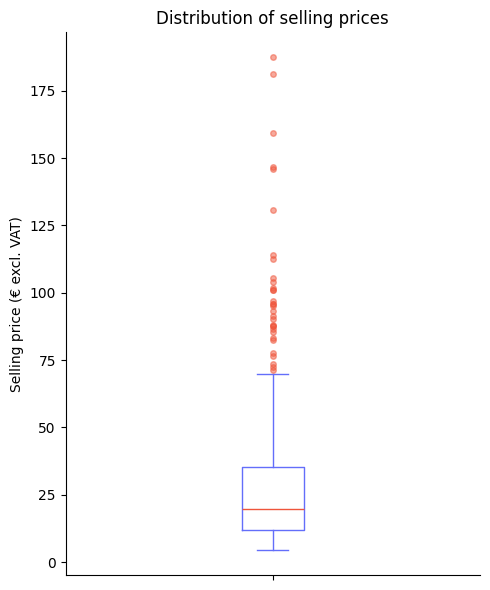

In [72]:
# Box plot of selling prices with pandas
fig, ax = plt.subplots(figsize=(5, 6))
d["price_excl_vat"].plot(
    kind="box",
    ax=ax,
    color={"boxes": "#636EFA", "whiskers": "#636EFA", "medians": "#EF553B", "caps": "#636EFA"},
    flierprops={
        "marker": "o",
        "markersize": 4,
        "markerfacecolor": "#EF553B",
        "markeredgecolor": "#EF553B",
        "alpha": 0.5,
    },
    patch_artist=False,
)
ax.set_title("Distribution of selling prices")
ax.set_ylabel("Selling price (€ excl. VAT)")
ax.set_xticklabels([""])
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

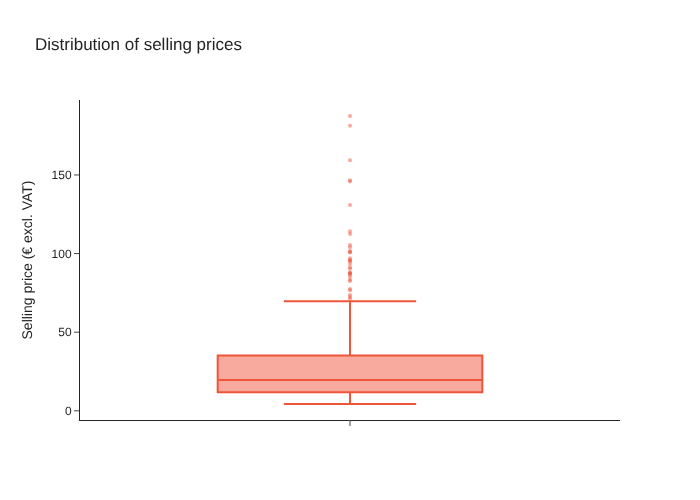

In [73]:
# The same with plotly express
fig = px.box(
    d,
    y="price_excl_vat",
    title="Distribution of selling prices",
    labels={"price_excl_vat": "Selling price (€ excl. VAT)"},
    template="simple_white",
    color_discrete_sequence=["#636EFA"],
    points="outliers",
)
fig.update_traces(marker=dict(color="#EF553B", size=4, opacity=0.5))
fig.update_layout(height=500)
fig.show()

**Conclusion.** Prices are concentrated between €11.75 (Q1) and €35.17 (Q3) excl. VAT, with a median around
€19.67. Many outliers sit above €70, up to €187.50.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">6.2 - Revenue</h3>
</div>

In [74]:
# Website revenue
total_revenue = d["revenue_excl_vat"].sum()
print(f"Total website revenue: {total_revenue:.2f} € excl. VAT")

Total website revenue: 119665.75 € excl. VAT


In [75]:
# Revenue per product
d[["post_title", "price_excl_vat", "total_sales", "revenue_excl_vat"]].head()

,post_title,price_excl_vat,total_sales,revenue_excl_vat
0,Pierre Jean Villa Saint-Joseph Préface 2018,20.166667,6.0,121.00
1,Pierre Jean Villa Saint-Joseph Rouge Tildé 2017,28.583333,9.0,257.25
2,Pierre Jean Villa Crozes-Hermitage Accroche Co...,17.333333,0.0,0.00
3,Pierre Jean Villa IGP Collines Rhodaniennes Ga...,11.750000,12.0,141.00
4,Pierre Jean Villa Côte Rôtie Carmina 2017,38.333333,3.0,115.00


In [76]:
# Top 20 by revenue
top20_revenue = d.nlargest(20, "revenue_excl_vat")[
    ["post_title", "product_type", "price_excl_vat", "total_sales", "revenue_excl_vat"]
]
top20_revenue

,post_title,product_type,price_excl_vat,total_sales,revenue_excl_vat
200,Champagne Egly-Ouriet Grand Cru Millésimé 2008,Champagne,187.500000,11.0,2062.500000
601,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,Champagne,159.416667,6.0,956.500000
201,Champagne Egly-Ouriet Grand Cru Brut Rosé,Champagne,66.250000,14.0,927.500000
596,Agnès Levet Côte Rôtie Améthyste 2017,Vin,34.333333,20.0,686.666667
672,Domaine des Comtes Lafon Volnay 1er Cru Santen...,Vin,95.833333,7.0,670.833333
448,Champagne Agrapart &amp; Fils Minéral Extra Br...,Champagne,72.333333,9.0,651.000000
440,Domaine des Comtes Lafon Volnay 1er Cru Santen...,Vin,87.500000,7.0,612.500000
566,Camille Giroud Clos de Vougeot 2016,Vin,145.833333,4.0,583.333333
661,Champagne Gosset Célébris Vintage 2007,Champagne,112.500000,5.0,562.500000
447,Champagne Agrapart &amp; Fils L'Avizoise Extra...,Champagne,93.333333,6.0,560.000000


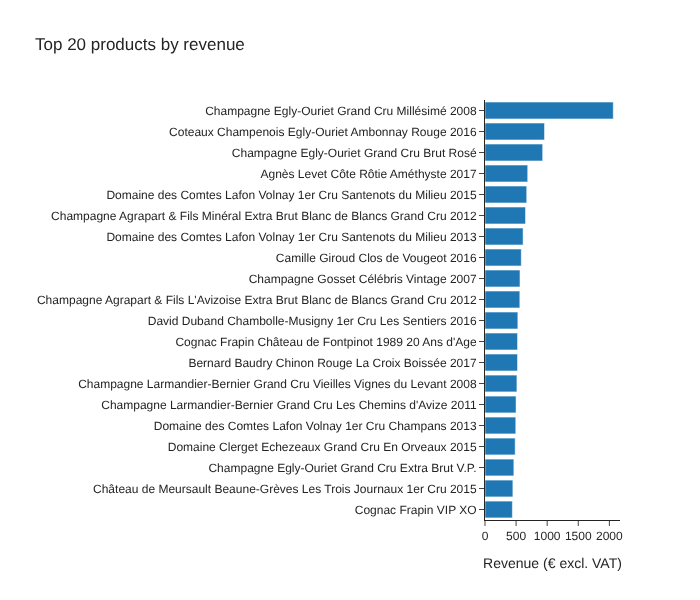

In [77]:
# Bar chart of the top 20 with plotly express
fig = px.bar(
    top20_revenue,
    x="revenue_excl_vat",
    y="post_title",
    orientation="h",
    title="Top 20 products by revenue",
    labels={"revenue_excl_vat": "Revenue (€ excl. VAT)", "post_title": ""},
    template="simple_white",
)
fig.update_layout(yaxis={"categoryorder": "total ascending"}, height=600)
fig.show()

In [78]:
# Average price of the top 20
print(f"Average price of the top 20 by revenue: {top20_revenue['price_excl_vat'].mean():.2f} € excl. VAT")

Average price of the top 20 by revenue: 94.07 € excl. VAT


In [79]:
# 80/20 on revenue
d_sorted = d.sort_values("revenue_excl_vat", ascending=False).copy()
d_sorted["cumulative_revenue"] = d_sorted["revenue_excl_vat"].cumsum()
d_sorted["cumulative_share"] = d_sorted["cumulative_revenue"] / d_sorted["revenue_excl_vat"].sum()

n_80 = (d_sorted["cumulative_share"] <= 0.8).sum()
print(f"{n_80} products make 80% of revenue, {n_80 / len(d):.1%} of the catalogue")

433 products make 80% of revenue, 60.7% of the catalogue


In [80]:
# Bottles sold in October
bottles_sold = d["total_sales"].sum()
print(f"Bottles sold in October: {int(bottles_sold)}")

Bottles sold in October: 5737


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">6.3 - Volume</h3>
</div>

In [81]:
# Top 20 by bottles sold
top20_volume = d.nlargest(20, "total_sales")[
    ["post_title", "product_type", "price_excl_vat", "total_sales", "revenue_excl_vat"]
]
top20_volume

,post_title,product_type,price_excl_vat,total_sales,revenue_excl_vat
370,Château De La Selve IGP Coteaux de l'Ardèche M...,Vin,8.250000,36.0,297.000000
122,Mas Laval IGP Pays d'Hérault Les Pampres Blanc...,Vin,8.250000,27.0,222.750000
175,I Fabbri Chianti Classico Lamole 2017,Vin,12.416667,24.0,298.000000
268,Bernard Baudry Chinon Rouge La Croix Boissée 2017,Vin,23.750000,22.0,522.500000
324,François Baur Pinot Noir Schlittweg 2017,Vin,10.583333,22.0,232.833333
596,Agnès Levet Côte Rôtie Améthyste 2017,Vin,34.333333,20.0,686.666667
664,Moulin de Gassac IGP Pays d'Hérault Guilhem Bl...,Vin,4.333333,20.0,86.666667
135,Xavier Frissant Touraine Amboise Chenin Les Pi...,Vin,9.666667,18.0,174.000000
574,Maurel Pays d'Oc Merlot 2018,Vin,4.833333,17.0,82.166667
584,Château Tour Haut-Caussan Médoc 2015,Vin,14.250000,17.0,242.250000


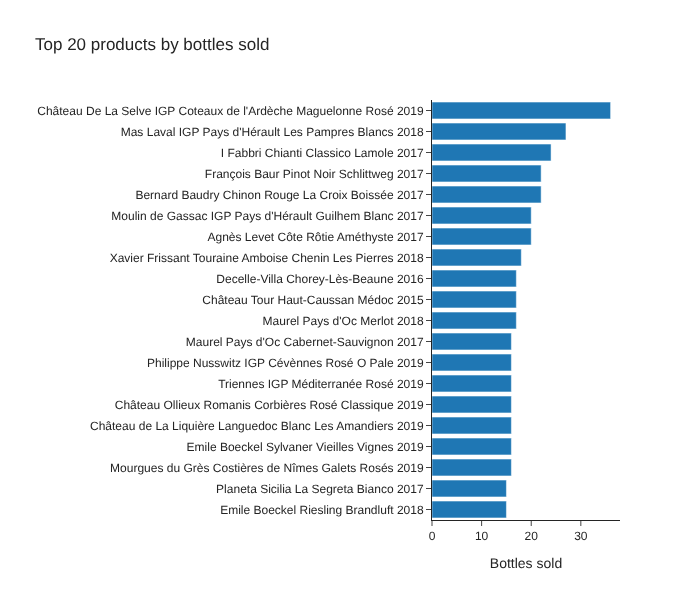

In [82]:
# Bar chart of the top 20 with plotly express
fig = px.bar(
    top20_volume,
    x="total_sales",
    y="post_title",
    orientation="h",
    title="Top 20 products by bottles sold",
    labels={"total_sales": "Bottles sold", "post_title": ""},
    template="simple_white",
)
fig.update_layout(yaxis={"categoryorder": "total ascending"}, height=600)
fig.show()

In [83]:
# 80/20 on volume
d_sorted_v = d.sort_values("total_sales", ascending=False).copy()
d_sorted_v["cumulative_sales"] = d_sorted_v["total_sales"].cumsum()
d_sorted_v["cumulative_share"] = d_sorted_v["cumulative_sales"] / d_sorted_v["total_sales"].sum()

n_80_v = (d_sorted_v["cumulative_share"] <= 0.8).sum()
print(f"{n_80_v} products make 80% of bottles sold, {n_80_v / len(d):.1%} of the catalogue")

432 products make 80% of bottles sold, 60.6% of the catalogue


In [84]:
# Stock value
print(f"Total stock value : {d['stock_value'].sum():,.0f} € at cost")
print(f"Bottles in stock  : {int(d['stock_quantity'].sum())}")

Total stock value : 277,225 € at cost
Bottles in stock  : 16707


The two rankings do not name the same products. By revenue, champagnes and grands crus lead, carried by their
price. By volume, entry-level wines lead, between €4 and €25 excl. VAT.

The 80/20 rule does not apply to this catalogue: it takes 433 products, 60.7% of the catalogue, to reach 80% of
revenue. Sales are spread evenly, with no dominant product, which is why the classic segmentation methods tested
later do not work here.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">6.4 - Markup</h3>
</div>

In [85]:
# Markup range
print(f"Lowest markup : {d['markup'].min() * 100:.2f} %")
print(f"Highest markup: {d['markup'].max() * 100:.2f} %")

Lowest markup : 29.50 %
Highest markup: 91.41 %


In [86]:
# Products sold below cost
d[d["markup"] < 0]

,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,id_web,virtual,downloadable,rating_count,...,post_type,post_mime_type,comment_count,price_excl_vat,revenue_excl_vat,unit_margin,markup,stock_value,coverage_months,never_sold


No product has a negative markup. In my first version, one row appeared here: the Champagne Egly-Ouriet Grand Cru
Blanc de Noirs, bought at €77.48 and sold at €12.65, presented as a product sold at a loss.

It was in fact an entry error, fixed automatically on loading by the rule on the purchase / selling price ratio.
The price kept is €126.50, which brings the ratio to 1.63, in line with the rest of the catalogue.

This empty table is therefore a result: it confirms that the fix was applied.

In [87]:
# Average markup by product type
markup_by_type = d.groupby("product_type")["markup"].mean().mul(100).round(2).reset_index()
markup_by_type

,product_type,markup
0,Champagne,39.82
1,Cognac,82.32
2,Gin,74.83
3,Huile d'olive,33.39
4,Vin,61.51
5,Whisky,81.74


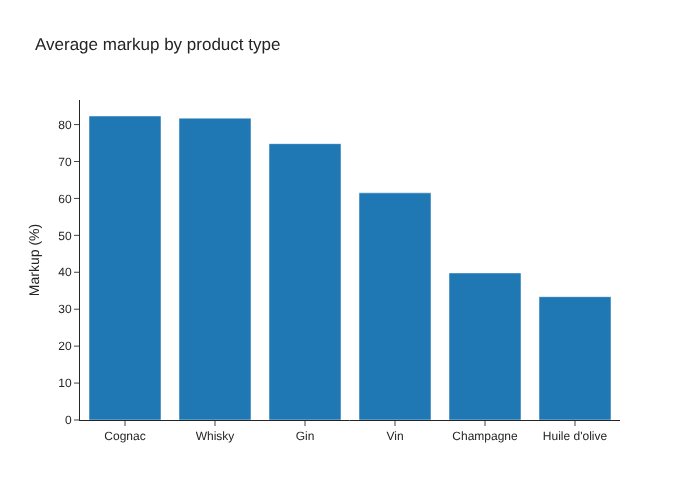

In [88]:
# Bar chart of the average markup by product type
markup_sorted = markup_by_type.sort_values("markup", ascending=False)

fig = px.bar(
    markup_sorted,
    x="product_type",
    y="markup",
    title="Average markup by product type",
    labels={"product_type": "", "markup": "Markup (%)"},
    template="simple_white",
)
fig.show()

Markup varies widely by category: 82% on cognacs and whiskies, against 40% on champagnes and 33% on olive oils.

This links to dormant stock: champagnes, which hold most of the slow-moving stock, are also among the least
profitable products. The capital is tied up in what earns the least.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 7 - Price anomaly detection</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">7.1 - Z-score</h3>
</div>

In [89]:
# Mean price
mean_price = d["price_excl_vat"].mean()
print(f"Mean price: {mean_price:.2f} €")

Mean price: 27.11 €


In [90]:
# Standard deviation
std_price = d["price_excl_vat"].std()
print(f"Standard deviation: {std_price:.2f}")

Standard deviation: 23.18


In [91]:
# Z-score
d["price_zscore"] = (d["price_excl_vat"] - mean_price) / std_price

In [92]:
# Price above which the z-score exceeds 3
z_threshold = mean_price + 3 * std_price
print(f"Prices above {z_threshold:.2f} € have a z-score above 3")

Prices above 96.64 € have a z-score above 3


**Conclusion.** The z-score gives a mean price of €27.11 excl. VAT and a first alert threshold at €96.64. It is very
sensitive to extreme values, such as prestige wines and champagnes, which pull the threshold up.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">7.2 - Interquartile range</h3>
</div>

In [93]:
# Dispersion
d["price_excl_vat"].describe()

count    713.000000
mean      27.108813
std       23.176698
min        4.333333
25%       11.750000
50%       19.666667
75%       35.166667
max      187.500000
Name: price_excl_vat, dtype: float64

In [94]:
# IQR threshold
q1 = d["price_excl_vat"].quantile(0.25)
q3 = d["price_excl_vat"].quantile(0.75)
iqr = q3 - q1
iqr_threshold = q3 + 1.5 * iqr
print(f"Prices above {iqr_threshold:.2f} € are flagged as outliers")

Prices above 70.29 € are flagged as outliers


In [95]:
# Number and share of flagged products
df_outliers = d[d["price_excl_vat"] > iqr_threshold]
share_outliers = len(df_outliers) / len(d) * 100
print(f"Flagged products : {len(df_outliers)}")
print(f"Share of catalogue: {share_outliers:.2f}%")

Flagged products : 32
Share of catalogue: 4.49%


**Conclusion.** The interquartile range, more robust to extreme values, gives a lower threshold of €70.29. It flags
32 products, 4.49% of the catalogue, as possible outliers. To confirm.

In [96]:
# Are these outliers justified? Check their purchase / selling price ratio
df_outliers = df_outliers.copy()
df_outliers["price_ratio"] = df_outliers["price_excl_vat"] / df_outliers["purchase_price"]
df_outliers[["post_title", "price_excl_vat", "purchase_price", "price_ratio"]].sort_values(
    by="price_ratio", ascending=False
)

,post_title,price_excl_vat,purchase_price,price_ratio
616,Wemyss Malts Single Cask Scotch Whisky Chocola...,77.500000,40.49,1.914053
222,Cognac Frapin Château de Fontpinot 1989 20 Ans...,130.833333,69.08,1.893939
617,Wemyss Malts Single Cask Scotch Whisky Choc 'n...,101.666667,54.24,1.874385
219,Cognac Frapin VIP XO,146.666667,78.25,1.874334
223,Cognac Frapin Cigar Blend,86.666667,46.71,1.855420
618,Wemyss Malts Single Cask Scotch Whisky Chai Ca...,95.000000,52.25,1.818182
220,Cognac Frapin Château de Fontpinot XO,90.416667,52.22,1.731457
675,Domaine des Comtes Lafon Volnay 1er Cru Champa...,95.833333,56.45,1.697668
229,Château de Meursault Puligny-Montrachet 1er Cr...,91.333333,53.80,1.697646
387,Domaine Des Croix Corton Charlemagne Grand Cru...,114.166667,67.95,1.680157


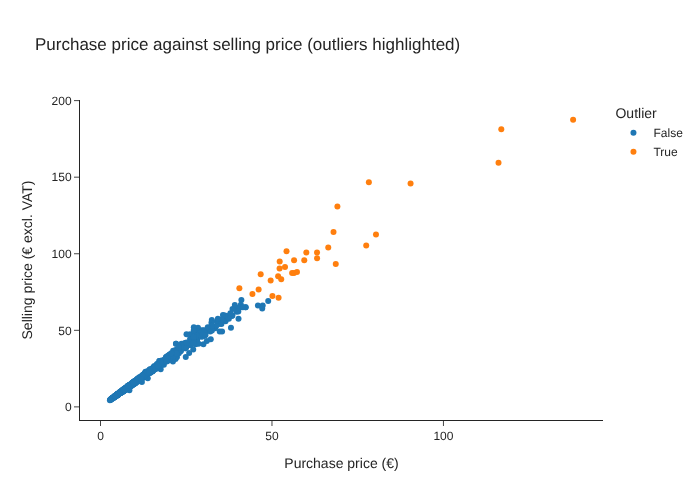

In [97]:
# Purchase price against selling price, outliers highlighted
fig = px.scatter(
    d,
    x="purchase_price",
    y="price_excl_vat",
    color=d["price_excl_vat"] > iqr_threshold,
    title="Purchase price against selling price (outliers highlighted)",
    labels={
        "purchase_price": "Purchase price (€)",
        "price_excl_vat": "Selling price (€ excl. VAT)",
        "color": "Outlier",
    },
    template="simple_white",
)
fig.show()

The table and the chart show that the 32 outliers follow the same purchase / selling price relationship as the
rest of the catalogue, with a ratio between 1.36 and 1.91. They are not anomalies but premium products: cognacs,
sipping whiskies, grands crus and prestige champagnes.

Applied to the price, the method finds no real anomaly and flags 4.49% of the catalogue for nothing. The problem
is not the algorithm but the variable: a price alone says nothing about whether a product is priced consistently.

The selling / purchase price ratio carries that information, because it is very stable in this catalogue. The
method kept uses it directly.

In [98]:
# Method kept: robust z-score (MAD) on the selling / purchase price ratio
anomalies = price_anomalies(df_erp)
print(f"{len(anomalies)} products flagged at MAD threshold {MAD_THRESHOLD}")
display(anomalies[["product_id", "price", "purchase_price", "ratio", "mad_score"]].round(2))

3 products flagged at MAD threshold 5


,product_id,price,purchase_price,ratio,mad_score
391,4864,8.3,9.99,0.83,-12.45
724,6324,92.0,99.00,0.93,-11.34
817,7196,31.0,31.20,0.99,-10.61


The method kept flags 3 products, all priced at or below their purchase price, with a ratio between 0.83 and 0.99.
No rule explains them, so they are not fixed but reported to the business.

The 4 certain anomalies of the catalogue, 3 negative prices and one price divided by 10, do not appear here: they
were fixed automatically on loading, as the quality report shows.

On the two variables tested, the result is clear: on the price, detection flags 32 products and no real anomaly;
on the purchase / selling price ratio, it finds the 4 anomalies and flags only 3 others, all of them real.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 8 - Segmentation and action list</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">8.1 - Coverage segments</h3>
</div>

In [99]:
# Coverage x stock value matrix
# The first bound is negative: otherwise the products with zero coverage
# (sold out after selling) would disappear from the table.
bounds = [-0.001, 0, 1, 3, 6, 12, np.inf]
labels = [
    "sold out",
    "up to 1 month",
    "1 to 3 months",
    "3 to 6 months",
    "6 to 12 months",
    "over 12 months (dormant)",
]

sold = d[~d["never_sold"]].copy()
sold["segment"] = pd.cut(sold["coverage_months"], bins=bounds, labels=labels)

segments = (
    sold.groupby("segment", observed=False)
    .agg(products=("product_id", "count"), stock_value=("stock_value", "sum"))
    .round(0)
)

# Never-sold products: split those holding stock from those with none
never = d[d["never_sold"]]
never_with_stock = never[never["stock_quantity"] > 0]
never_no_stock = never[never["stock_quantity"] == 0]
segments.loc["never sold, with stock"] = [len(never_with_stock), round(never_with_stock["stock_value"].sum())]
segments.loc["never sold, no stock"] = [len(never_no_stock), 0]
segments["share_of_stock"] = (segments["stock_value"] / segments["stock_value"].sum() * 100).round(1)

# Formatting
table = segments.copy()
table["stock_value"] = table["stock_value"].map(lambda v: f"{v:,.0f} €")
table["share_of_stock"] = table["share_of_stock"].map(lambda v: f"{v:.1f} %")
table.columns = ["Products", "Stock value", "Share of stock"]
table.index.name = "Coverage"

display(table)
print("Total products:", int(segments["products"].sum()), "of", len(d))

,Products,Stock value,Share of stock
Coverage,,,
sold out,23,0 €,0.0 %
up to 1 month,27,"2,501 €",0.9 %
1 to 3 months,461,"101,899 €",36.8 %
3 to 6 months,146,"43,517 €",15.7 %
6 to 12 months,7,"19,337 €",7.0 %
over 12 months (dormant),24,"95,012 €",34.3 %
"never sold, with stock",3,"14,959 €",5.4 %
"never sold, no stock",22,0 €,0.0 %


Total products: 713 of 713


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">8.2 - Where the capital sleeps</h3>
</div>

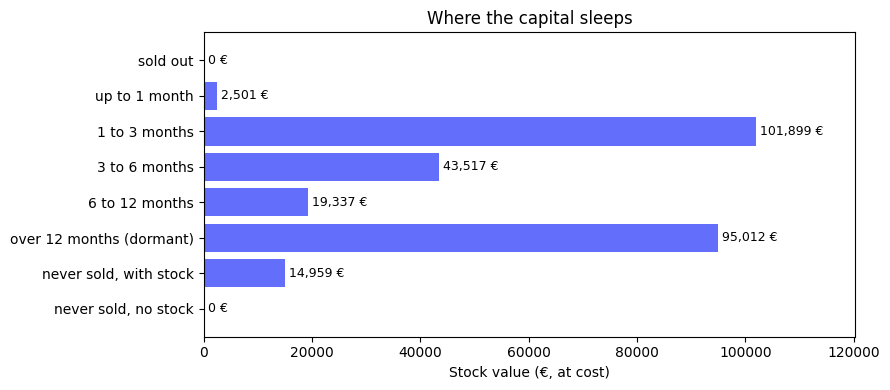

In [100]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(segments.index.astype(str), segments["stock_value"], color="#636EFA")
ax.set_xlabel("Stock value (€, at cost)")
ax.set_title("Where the capital sleeps")
for i, v in enumerate(segments["stock_value"]):
    ax.text(v, i, f" {v:,.0f} €", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, segments["stock_value"].max() * 1.18)
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">8.3 - Action list</h3>
</div>

In [101]:
# Four business rules, prioritised by the value at stake
def action(row):
    if row["never_sold"] and row["stock_quantity"] > 0:
        return "never sold, with stock: consider clearing it"
    if row["never_sold"]:
        return "no sales and no stock: check whether the product is discontinued"
    if row["coverage_months"] > 12:
        return "dormant stock: suspend restocking"
    if row["coverage_months"] < 1:
        return "stock-out risk: reorder"
    return None


d["action"] = d.apply(action, axis=1)
actions = d[d["action"].notna()].sort_values("stock_value", ascending=False)

columns = [
    "product_id",
    "post_title",
    "stock_quantity",
    "total_sales",
    "coverage_months",
    "stock_value",
    "markup",
    "action",
]
actions = actions[columns]

print(f"{len(actions)} recommended actions")
print(actions["action"].value_counts().to_string())
display(actions.head(15).round(2))

actions.to_excel(DATA_OUT / "priority_actions.xlsx", index=False)
print(f"\nExported to {(DATA_OUT / 'priority_actions.xlsx').relative_to(ROOT)}")

73 recommended actions
action
dormant stock: suspend restocking                                   24
stock-out risk: reorder                                             24
no sales and no stock: check whether the product is discontinued    22
never sold, with stock: consider clearing it                         3


,product_id,post_title,stock_quantity,total_sales,coverage_months,stock_value,markup,action
601,5892,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...,98,6.0,16.33,11373.88,0.37,dormant stock: suspend restocking
661,6126,Champagne Gosset Célébris Vintage 2007,138,5.0,27.60,11085.54,0.40,dormant stock: suspend restocking
447,5025,Champagne Agrapart &amp; Fils L'Avizoise Extra...,136,6.0,22.67,9329.60,0.36,dormant stock: suspend restocking
202,4355,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,97,0.0,NaN,7515.56,0.36,"never sold, with stock: consider clearing it"
197,4337,Champagne Mailly Grand Cru Les Echansons 2007,145,0.0,NaN,7090.50,0.41,"never sold, with stock: consider clearing it"
199,4350,Champagne Egly-Ouriet Grand Cru Extra Brut V.P.,145,7.0,20.71,6858.50,0.40,dormant stock: suspend restocking
206,4359,Champagne Larmandier-Bernier Grand Cru Les Che...,112,7.0,16.00,5816.16,0.37,dormant stock: suspend restocking
76,4150,Champagne Mailly Grand Cru Intemporelle 2010,123,6.0,20.50,4360.35,0.39,dormant stock: suspend restocking
198,4348,Champagne Egly-Ouriet Grand Cru Brut Tradition,125,5.0,25.00,4345.00,0.41,dormant stock: suspend restocking
195,4334,Champagne Gosset Grand Blanc de Blancs,142,7.0,20.29,4261.42,0.36,dormant stock: suspend restocking



Exported to data/processed/priority_actions.xlsx


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">8.4 - The ten products holding the most capital</h3>
</div>

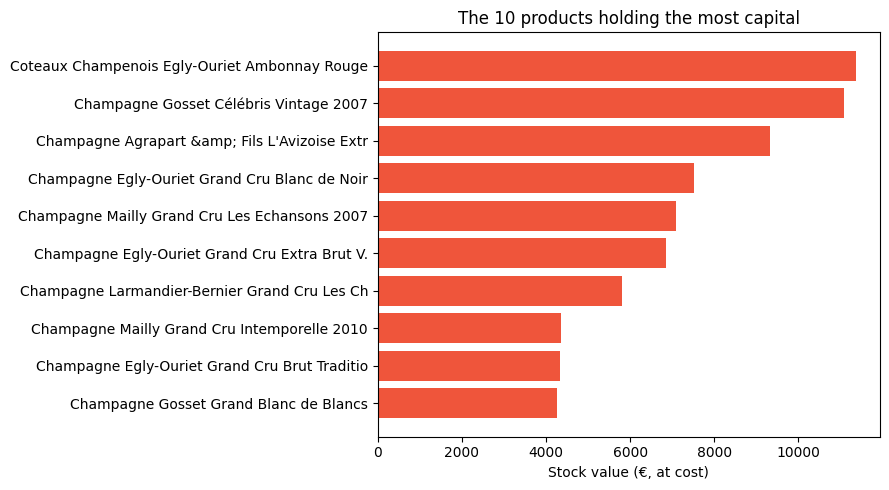

In [102]:
top = actions.head(10)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["post_title"].str.slice(0, 45)[::-1], top["stock_value"][::-1], color="#EF553B")
ax.set_xlabel("Stock value (€, at cost)")
ax.set_title("The 10 products holding the most capital")
plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">8.5 - Sold-out products</h3>
</div>

In [103]:
# Sold out after selling during the month
sold_out = d[(~d["never_sold"]) & (d["coverage_months"] == 0)]
print(
    len(sold_out),
    "sold-out products |",
    int(sold_out["total_sales"].sum()),
    "bottles sold |",
    round(sold_out["revenue_excl_vat"].sum()),
    "€ excl. VAT",
)

23 sold-out products | 194 bottles sold | 5516 € excl. VAT


In [104]:
# Where does the dormant capital sit, by product type?
holding = d[(d["coverage_months"] > 12) | (d["never_sold"] & (d["stock_quantity"] > 0))]
summary = holding.groupby("product_type").agg(
    products=("product_id", "count"), stock_value=("stock_value", "sum")
)
summary["share_of_total_stock"] = (summary["stock_value"] / d["stock_value"].sum() * 100).round(1)
print(f"{len(holding)} products hold {holding['stock_value'].sum():,.0f} €, "
      f"{holding['stock_value'].sum() / d['stock_value'].sum():.1%} of the stock value")
display(summary.sort_values("stock_value", ascending=False).round({"stock_value": 0, "share_of_total_stock": 1}))

27 products hold 109,971 €, 39.7% of the stock value


,products,stock_value,share_of_total_stock
product_type,,,
Champagne,23,105879.0,38.2
Vin,2,2230.0,0.8
Huile d'olive,1,1509.0,0.5
Cognac,1,353.0,0.1


The products at the top of the list are grower champagnes, with a markup between 36% and 41% against 61% for the
catalogue's median. The capital sleeps in the least profitable products.

In all, **27 products hold 39.7% of the stock value** for little or no revenue: 24 cover more than twelve months of
sales, and 3 did not sell at all while holding €14,959 of stock. **23 of these 27 are champagnes.**

The 22 other never-sold products have no stock at all: they could not sell. Whether they are discontinued or
waiting for a delivery is a question for the purchasing manager.

At the other end, 23 products sold out after selling 194 bottles during the month, €5,516 excl. VAT. Until they are
restocked, they are lost sales.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 9 - Correlations</h2>
</div>

In [105]:
# Pearson against Spearman
columns = ["price_excl_vat", "total_sales", "stock_quantity", "markup"]
comp = (
    pd.DataFrame(
        {
            "Spearman": d[columns].corr(method="spearman")["total_sales"],
            "Pearson": d[columns].corr(method="pearson")["total_sales"],
        }
    )
    .drop("total_sales")
    .round(2)
)
display(comp)

corr = d[columns].corr(method="spearman")

,Spearman,Pearson
price_excl_vat,-0.71,-0.52
stock_quantity,0.76,0.44
markup,-0.02,-0.03


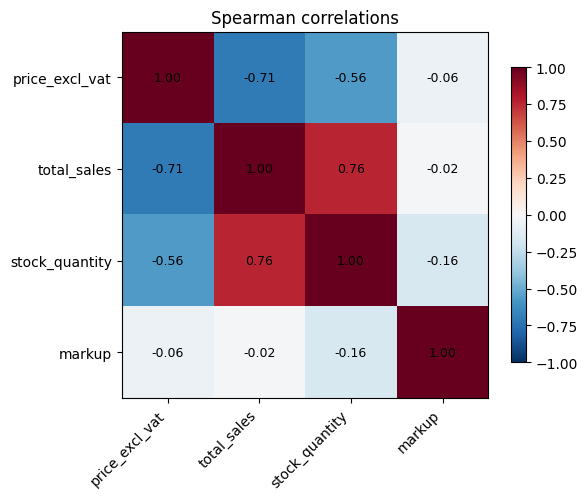

In [106]:
# Spearman heatmap
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Spearman correlations")
fig.colorbar(im, shrink=0.8)
plt.tight_layout()
plt.show()

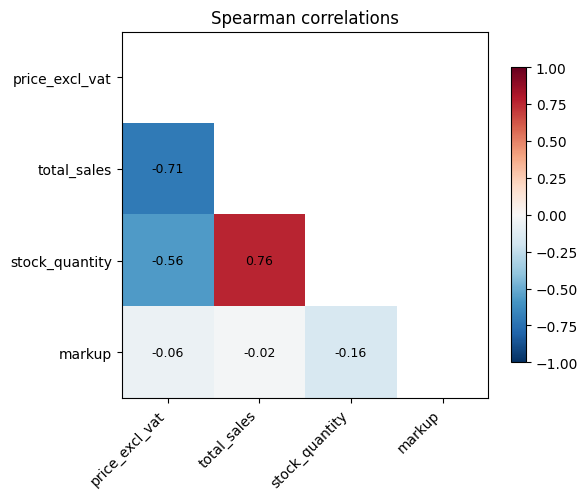

In [107]:
# Half heatmap with a mask
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.mask(mask), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        if not mask[i, j]:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Spearman correlations")
fig.colorbar(im, shrink=0.8)
plt.tight_layout()
plt.show()

The more expensive a wine, the less it sells (−0.71). And the more a product sells, the larger its stock (0.76):
order volumes follow expected sales. Markup correlates with nothing: pricing is consistent across the catalogue.

Pearson gave −0.52 and 0.44 on the same data. The gap comes from the strongly skewed distributions (median price
€19.67 excl. VAT, maximum €187.50), on which Pearson understates the real relationships.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 10 - Assumptions and limits</h2>
</div>

**Assumptions**

- `total_sales` covers October only: the client's brief says the sales run from 1 to 31 October.
- VAT is not in the files: 20% is assumed, the standard French rate on wine and spirits, and kept in a single constant. The three olive oils normally carry the reduced 5.5% rate.
- Purchase prices are excluding VAT, as is the accounting convention.

**Limits**

- One month of history, so no seasonality, although October comes just before the year-end peak. A product classed as dormant may simply be seasonal.
- The coverage thresholds (1 month to reorder, 12 months for dormant stock) are conventions. They should be set with the purchasing manager, based on supplier lead times.
- The price anomaly threshold is calibrated on a single export, to review after the second month.
- The 109 products the ERP declares offline are not analysed, although their stock exists.
- The €25 gift card is kept as a product: 7 sold, €146 of revenue excl. VAT.
- The tool checks that the exports are consistent, not that they are true: an entry error consistent with the rest of the catalogue would go unnoticed.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 11 - Library versions</h2>
</div>

In [108]:
import pandera
import matplotlib

print("Python", sys.version.split()[0])
print("pandas", pd.__version__)
print("numpy", np.__version__)
print("pandera", pandera.__version__)
print("matplotlib", matplotlib.__version__)

Python 3.13.16
pandas 3.0.0
numpy 2.4.2
pandera 0.33.1
matplotlib 3.10.8


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Step 12 - Excel export of the final dataset</h2>
</div>

In [109]:
# Export the final dataset to share it with the teams
d.to_excel(DATA_OUT / "final_dataset.xlsx", index=False)
print("final_dataset.xlsx exported to data/processed")

final_dataset.xlsx exported to data/processed


## Conclusion

**What was fixed**

Two indicators I presented in my first version were wrong. Average stock coverage drops from 35.62 to 2.98 months,
once a division by 12 applied to sales that were already monthly is removed. And 25 never-sold products are back
in the analysis: 3 of them, holding €14,959 of stock, had an infinite coverage replaced by 0, which ranked them
among the fastest-moving products; the 22 others, with neither sales nor stock, dropped out of the calculation
without a trace.

Every amount is now excluding VAT, on the same basis as purchase prices. Ten validation rules replace optional
checks, and no row is rejected without being counted. Entry errors are fixed by rule, not by ID, so the processing
can run on next month's export without rewriting a line of code.

**Recommendations to Bottleneck**

- Suspend restocking of the 24 products whose stock covers more than twelve months of sales: €95,012 tied up, 21 of them champagnes.
- Decide on the 3 never-sold products that hold €14,959 of stock, after checking the price of the Blanc de Noirs, entered at €12.65.
- Reorder the 23 sold-out products that sold 194 bottles in the month: €5,516 excl. VAT of October sales that stop until they are back in stock.
- Check whether the 22 products with neither sales nor stock are discontinued, and take them off the website if so.
- Check the three products priced at or below their purchase price, the two stock statuses that contradict their quantity, the three products declared online but missing from the link table, and the product on the website but declared offline in the ERP.